In [1]:
import pandas as pd

SEED = 22

In [2]:
df = pd.read_csv('../data/processed/data_symbol.csv')
df.index = df['Unnamed: 0']
df.index.name = 'ID'
df = df.drop(columns=['Unnamed: 0'])

In [3]:
df_metadata = pd.read_csv('../data/processed/metadata_ad_control.csv')

In [4]:
# Remove outlier
df_metadata = df_metadata[df_metadata['geo_accession'].isin(df.index)]

In [5]:
df = df.merge(df_metadata, left_index=True, right_on='geo_accession')
df.index = df['geo_accession']
df = df.drop(columns=['geo_accession'])

In [6]:
df['disease_status_ch2'] = df['disease_status_ch2'].map({'Alzheimer\'s disease' : 1, 'non-demented': 0})
df['gender_ch2'] = df['gender_ch2'].map({'female' : 1, 'male': 0})

In [7]:
from sklearn.model_selection import train_test_split

cols = ['disease_status_ch2']
stratify = df[cols]

X = df.drop(columns=['disease_status_ch2'])
y = df['disease_status_ch2']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=SEED, stratify=stratify)

In [8]:
# Save train and test ids
df_train = pd.DataFrame(X_train.index.values, columns=['ID'])
df_train = df_train.merge(y_train, left_on='ID', right_index=True)

df_test = pd.DataFrame(X_test.index.values, columns=['ID'])
df_test = df_test.merge(y_test, left_on='ID', right_index=True)

df_train.to_csv('../data/processed/train.csv', index=False)
df_test.to_csv('../data/processed/test.csv', index=False)

In [9]:
y_train.value_counts(normalize=True)

disease_status_ch2
1    0.663978
0    0.336022
Name: proportion, dtype: float64

In [10]:
y_test.value_counts(normalize=True)

disease_status_ch2
1    0.659574
0    0.340426
Name: proportion, dtype: float64

In [11]:
X_train.head()

,OR2T6,DKFZp686D0972,NOTCH2NL,SPIRE1,HSP90AA5P,SEMA4C,LOC728217,PTK7,RAC3,EEF2K,...,ABCB8,SLC4A5,ABCA6,CYP8B1,SLC6A13,NAT1,ABCC1,UBC,age_ch2,gender_ch2
geo_accession,,,,,,,,,,,,,,,,,,,,,
GSM1423843,0.035094,0.074600,0.061674,-0.034617,-0.097585,0.048608,-0.025984,0.080745,0.065282,0.049432,...,-0.050796,-0.000387,0.067265,-0.021157,-0.047822,0.024767,-0.031776,0.130085,73,0
GSM1424203,0.029174,-0.040935,0.220564,0.501817,-0.341664,0.290696,-0.237790,0.073794,0.025889,-0.034635,...,-0.011922,-0.030254,-0.183182,0.048412,0.127948,-0.109052,-0.029987,0.088521,61,0
GSM1423849,0.069388,0.047501,0.100944,-0.035476,0.004773,0.018287,0.015608,0.083217,0.085152,0.102462,...,-0.039547,0.006316,-0.104524,0.074315,-0.048155,0.017138,0.030511,0.235409,83,1
GSM1424118,0.059048,0.147160,-0.073916,0.041597,0.007263,0.044078,0.018193,-0.035383,-0.090671,-0.090001,...,-0.005852,-0.042290,-0.049416,0.054740,0.030668,-0.058393,0.044615,0.202461,68,0
GSM1423981,0.009974,0.061912,0.221157,0.370889,-0.252091,0.459251,-0.241588,0.007826,0.089263,0.045622,...,0.196446,0.026657,-0.077909,0.060532,0.145318,0.021072,-0.059341,-0.055879,88,1


In [12]:
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.dummy import DummyClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

dummy_clf = DummyClassifier().fit(X_train.drop(columns=['age_ch2', 'gender_ch2']), y_train)
y_pred = dummy_clf.predict(X_test.drop(columns=['age_ch2', 'gender_ch2']))
pred_proba = dummy_clf.predict_proba(X_test.drop(columns=['age_ch2', 'gender_ch2']))

accuracy = balanced_accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, pred_proba[:, 1])

print(f'Balanced accuracy score: {accuracy * 100:.1f}%')
print(f'AUC score: {auc * 100:.1f}%')

Balanced accuracy score: 50.0%
AUC score: 50.0%


Sensitivity: 100.0%
Specificity: 0.0%


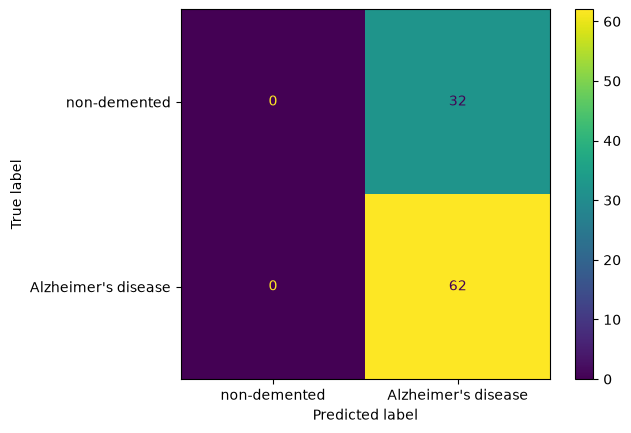

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['non-demented', 'Alzheimer\'s disease'])

sensitivity = cm[1][1] / (cm[1][0] + cm[1][1])
specificity = cm[0][0] / (cm[0][0] + cm[0][1])

print(f'Sensitivity: {sensitivity * 100:.1f}%')
print(f'Specificity: {specificity * 100:.1f}%')

disp.plot()
plt.show()

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV

def run_pipeline(X_train, y_train, X_test, y_test):
    clf = LogisticRegressionCV(
        cv=5,
        random_state=SEED,
        scoring='roc_auc',
        l1_ratios=(0,),
        use_legacy_attributes=False,
        class_weight='balanced')

    pipe = Pipeline([('scaler', StandardScaler()), ('clf', clf)])

    pipe.fit(pd.DataFrame(X_train), y_train)
    y_pred = pipe.predict(pd.DataFrame(X_test))
    pred_proba = pipe.predict_proba(pd.DataFrame(X_test))

    accuracy = balanced_accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, pred_proba[:, 1])

    print(f'C: {pipe.named_steps["clf"].C_}')
    print(f'\nBalanced accuracy score: {accuracy * 100:.1f}%')
    print(f'AUC score: {auc * 100:.1f}%')

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['non-demented', 'Alzheimer\'s disease'])

    sensitivity = cm[1][1] / (cm[1][0] + cm[1][1])
    specificity = cm[0][0] / (cm[0][0] + cm[0][1])

    print(f'\nSensitivity: {sensitivity * 100:.1f}%')
    print(f'Specificity: {specificity * 100:.1f}%')

    disp.plot()
    plt.show()

### Age alone

C: 0.0001

Balanced accuracy score: 77.0%
AUC score: 88.7%

Sensitivity: 79.0%
Specificity: 75.0%


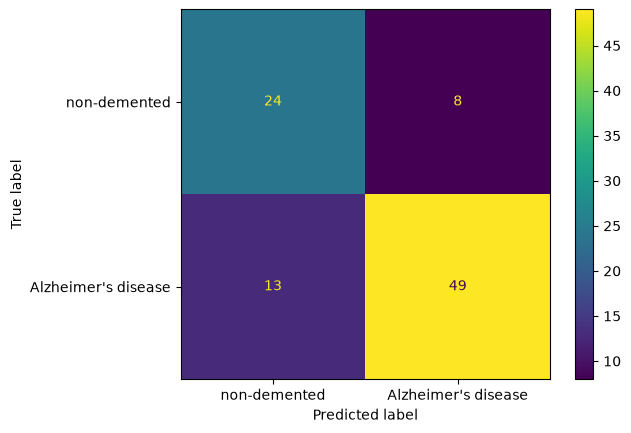

In [15]:
run_pipeline(X_train['age_ch2'], y_train, X_test['age_ch2'], y_test)

### Gender alone

C: 0.0001

Balanced accuracy score: 63.4%
AUC score: 63.4%

Sensitivity: 54.8%
Specificity: 71.9%


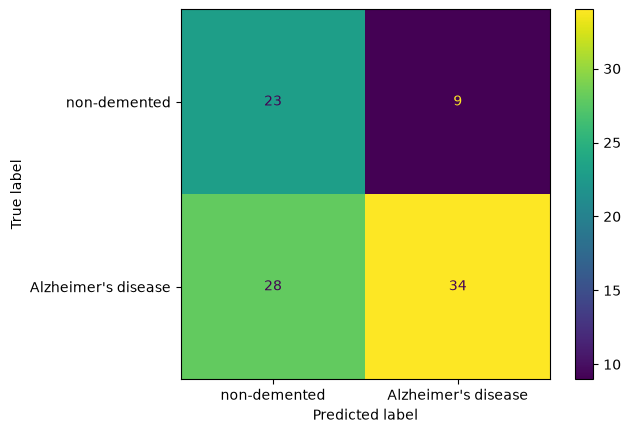

In [16]:
run_pipeline(X_train['gender_ch2'], y_train, X_test['gender_ch2'], y_test)

### Age and gender

C: 0.3593813663804626

Balanced accuracy score: 77.0%
AUC score: 87.9%

Sensitivity: 79.0%
Specificity: 75.0%


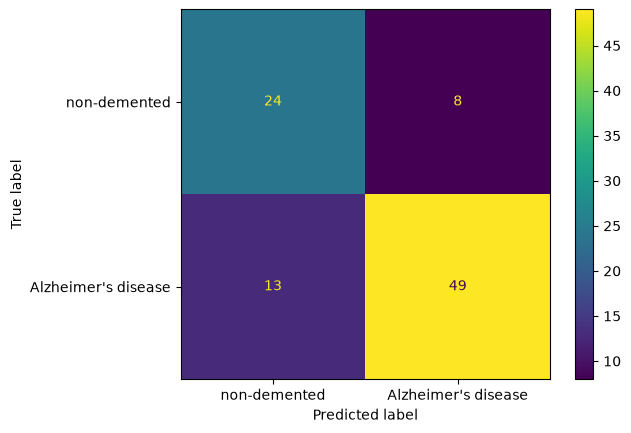

In [17]:
run_pipeline(
    X_train[['gender_ch2', 'age_ch2']],
    y_train,
    X_test[['gender_ch2', 'age_ch2']],
    y_test)